In [1]:
%matplotlib inline
from lesson_setup import *

In [2]:
train, test = next(GroupShuffleSplit(n_splits=1, test_size=0.4,
    random_state=SEED).split(index, groups=groups))
train2, validation2 = next(GroupShuffleSplit(n_splits=1, test_size=1/3,
    random_state=SEED+1).split(train, groups=groups[train]))
train_final, validation = train[train2], train[validation2]
group_sets = [set(groups[x]) for x in (train_final, validation, test)]
assert not (group_sets[0] & group_sets[1] or group_sets[0] & group_sets[2]
            or group_sets[1] & group_sets[2])
assert set(np.concatenate([train_final, validation, test])) == set(index)
print("Train / validation / test cases:", [list(map(int, sorted(g))) for g in group_sets])

Train / validation / test cases: [[0, 1], [2], [3, 4]]


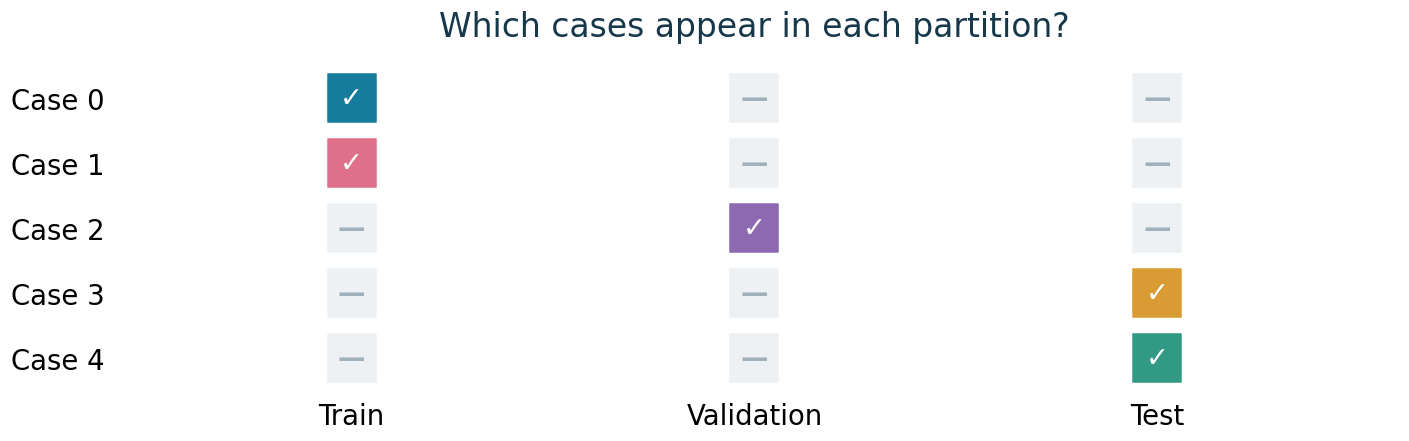

In [3]:
plot_partitions(groups, [train_final, validation, test], ["Train", "Validation", "Test"])